# Market Data, Candlestick Charts, and Returns

| Key              | Value |
|:-----------------|:------|
| **Course Codes** | BBT 4206 and BFS 4102 |
| **Course Names** | BBT 4206: Business Intelligence II (Week 7-9 of 13)<br>BFS 4102: Advanced Business Data Analytics (Week 1-3 of 13) |
| **Semester**     | September to November 2026 |
| **Lecturer**     | Allan Omondi |
| **Contact**      | aomondi@strathmore.edu |
| **Note**         | The lecture contains both theory and practice.<br/>This notebook forms part of the practice.<br/>It is intended for educational purposes only, and nothing in it is investment advice.<br/>Recommended citation: [BibTex](https://raw.githubusercontent.com/course-files/TimeSeriesForecastingandNeuralNetworks/refs/heads/main/RecommendedCitation.bib) |


**Remote Environments:**

Do your best to set up your local environment as guided during the lab, however, if you have challenges setting it up, then you can use the following remote environments temporarily for the lab:<br/>

[![Colab](https://img.shields.io/badge/Open-Colab-orange?logo=googlecolab)](
https://colab.research.google.com/github/course-files/TimeSeriesForecastingandNeuralNetworks/blob/main/1_market_data_and_candlesticks.ipynb) (preferred option)

[![Codespaces](https://img.shields.io/badge/Open-Codespaces-blue?logo=github)](
https://github.com/codespaces/new/course-files/TimeSeriesForecastingandNeuralNetworks) (alternative)

## What you will learn in this notebook

By the end of this notebook you should be able to:

1. Explain what each column in a daily price table (Open, High, Low, Close, Volume) means, and read a candlestick chart.
2. Explain why the lab forecasts a stock using **several predictors** instead of its own past price alone.
3. Load a market data snapshot, and check it for the problems that most often break a forecasting project.
4. Explain the difference between a price, a simple return and a log return, and identify why the rest of the lab works with returns.

**Prerequisites:** the theory lecture on financial markets and time series data and basic pandas.

## Narrative

A portfolio manager who has to decide what to do with a stock tomorrow looks at many things at once: how the stock has behaved recently, how volatile it has been, how much was traded, what the whole market is doing, whether investors are nervous, what is happening to interest rates and the dollar, and perhaps what oil and gold are doing.

In this lab you will build forecasting models that use all of that information, and you will learn how to test honestly whether the extra information helps. The question is the same for every notebook:

> **Using only what we know at the close of today, how well can we forecast the closing price of tomorrow, and does the extra information beat simply saying "tomorrow will be the same as today"?**

That second part of the question is the most important one in the whole module. Keep it in mind.

## Step 1: Set Up the Notebook

The first cell confirms which Python interpreter this notebook is using. If it does not point to the virtual environment you created for this lab, stop and fix that first (see `0_setup_instructions/`). Installing packages into the wrong interpreter is the most common reason for an `ImportError` that "should not happen".

The second cell imports the libraries. All the "heavy lifting" for this lab is in the `tslab` folder next to the notebooks. Read those files; they are short, and they are commented to support your comprehension.

In [31]:
import os
import sys
import subprocess

print("Python interpreter:", sys.executable)
print("Python version    :", sys.version.split()[0])

# Google Colab starts with an empty workspace, so we fetch the lab files first.
# This block does nothing in your local environment (your laptop).
if "google.colab" in sys.modules and not os.path.exists("tslab"):

    # Run the command "git clone <url>" to download the course repository
    # into a new folder in the current directory.
    # Each list item is one argument, so no shell is involved and spaces do not need quoting.
    # check=True raises an error (CalledProcessError) if the command fails,
    # e.g. no network or the folder already exists, instead of failing silently.
    subprocess.run(["git", "clone", "https://github.com/course-files/TimeSeriesForecastingandNeuralNetworks.git"], check=True)

    # Relative paths start from the folder specified. Example: `pd.read_csv("data/prices.csv")`
    # now looks for <named_folder>/data/prices.csv. This is why requirements/colab.txt works
    # in the next line.
    os.chdir("TimeSeriesForecastingandNeuralNetworks")

    # Install the packages listed in requirements/colab.txt.
    # sys.executable is the full path to the Python running this notebook, so
    # "-m pip" uses that interpreter's pip and installs into the same environment.
    # -q (quiet) cuts down pip's output; -r reads the package list from the file.
    # check=True stops the notebook with an error if the installation fails.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements/colab.txt"], check=True)
    print("Colab workspace prepared.")

Python interpreter: c:\Users\aomondi\Documents\GitHub\Teaching\TimeSeriesForecastingandNeuralNetworks\.venv\Scripts\python.exe
Python version    : 3.12.10


In [32]:
# Data handling and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf
from IPython.display import Image, display

# Our own helper package (see the `tslab` folder)
from tslab import config
from tslab.data import load_market_data, data_quality_report

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)

## Step 2: The Target and the Predictors

The **target** is the daily closing price of one stock. The **predictors** are the other series we give the model. Each was chosen because there is an economic reason to believe it carries information about the stock.

In [33]:
print("Target stock:", config.TARGET_TICKER)
display(pd.DataFrame({"Yahoo Finance symbol": config.PREDICTOR_TICKERS}))

Target stock: NVDA


,Yahoo Finance symbol
SP500,^GSPC
TECH,XLK
VIX,^VIX
US10Y,^TNX
USD,DX-Y.NYB
BRENT,BZ=F
GOLD,GC=F


| Predictor | What it measures | Why it might help forecast the stock |
|:----------|:-----------------|:-------------------------------------|
| **SP500** | The broad US stock market | Most stocks move with the market. |
| **TECH** | A fund holding technology companies | Captures the behaviour of the stock's own sector. |
| **VIX** | The market's expected volatility (the "fear index") | Nervous markets behave differently from calm ones. |
| **US10Y** | The yield on 10-year US government bonds | Interest rates change how investors value company profits. |
| **USD** | The strength of the US dollar | A strong dollar reduces the value of overseas sales for multinational companies. |
| **BRENT** | The price of Brent crude oil | A signal of economic activity and costs. |
| **GOLD** | The price of gold | Investors move to gold when they are afraid. |

**A word of caution before we start.** An economic narrative is a reason to test a predictor. It is not evidence that the predictor works. In this lab we treat every narrative as a hypothesis, and we use the data to decide.

**A note on timing.** The stock and the S&P 500 close at the same moment. Today's market move, therefore, cannot be used to forecast today's stock move, because we only learn it when the day is over. What we can use is the market's move up to and including today to forecast tomorrow. Every feature in this lab respects that rule.

## Step 3: Load the Data

The data was downloaded once, on a fixed date, and saved in the `data` folder. Everyone in the class loads the same files, so everyone gets the same numbers. This is deliberate: if your colleague's RMSE significantly differs from yours, you can look for a mistake in the code, not in the data.

The function `load_market_data` does three things for us:

1. It reads the stock file and the predictor file.
2. It aligns them on the stock's trading days. The markets do not close on the same public holidays, so some predictor values are missing on some days. We carry the last known value **forward** for up to three days. We never fill backwards, because that would copy a value from the future into the past.
3. It returns one table with one row per trading day.

In [34]:
data = load_market_data()
data.head()

Loaded 2970 trading days of NVDA, 2015-01-02 to 2026-10-23, with 7 predictor series.


,Open,High,Low,Close,Volume,SP500,TECH,VIX,US10Y,USD,BRENT,GOLD
Date,,,,,,,,,,,,
2015-01-02,0.481884,0.485475,0.474223,0.481884,113680000,2058.199951,18.041683,17.790001,2.123,91.080002,56.419998,1186.000000
2015-01-05,0.481884,0.483320,0.471590,0.473745,197952000,2020.579956,17.766272,19.920000,2.039,91.379997,53.110001,1203.900024
2015-01-06,0.474463,0.474942,0.458903,0.459381,197764000,2002.609985,17.552057,21.120001,1.963,91.500000,51.099998,1219.300049
2015-01-07,0.462733,0.466802,0.456748,0.458185,321808000,2025.900024,17.700695,19.309999,1.954,91.889999,51.150002,1210.599976
2015-01-08,0.463451,0.478293,0.463212,0.475420,283780000,2062.139893,18.089775,17.010000,2.016,92.370003,50.959999,1208.400024


In [35]:
data.tail()

,Open,High,Low,Close,Volume,SP500,TECH,VIX,US10Y,USD,BRENT,GOLD
Date,,,,,,,,,,,,
2026-10-19,218.100006,219.619995,214.699997,217.089996,98684700,7690.729980,185.960007,18.440001,5.136,101.980003,109.550003,4160.100098
2026-10-20,215.979996,218.460007,212.770004,216.470001,79609100,7712.569824,185.440002,17.309999,5.117,101.730003,108.790001,4142.600098
2026-10-21,220.960007,222.190002,217.660004,221.970001,87085700,7757.169922,188.539993,16.680000,5.146,101.779999,108.820000,4150.000000
2026-10-22,217.130005,218.880005,211.259995,212.210007,125407600,7663.430176,182.339996,19.030001,4.953,101.610001,113.169998,4060.399902
2026-10-23,210.990005,213.850006,210.179993,210.960007,79987200,7623.680176,183.229996,19.450001,4.988,101.809998,116.720001,4007.899902


### Confirm the Loaded Data

Run these checks every time you receive a dataset, before you model anything.

In [36]:
print("The number of observations and variables:", data.shape)
print()
data.info()

The number of observations and variables: (2970, 12)

<class 'pandas.DataFrame'>
DatetimeIndex: 2970 entries, 2015-01-02 to 2026-10-23
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    2970 non-null   float64
 1   High    2970 non-null   float64
 2   Low     2970 non-null   float64
 3   Close   2970 non-null   float64
 4   Volume  2970 non-null   int64  
 5   SP500   2970 non-null   float64
 6   TECH    2970 non-null   float64
 7   VIX     2970 non-null   float64
 8   US10Y   2970 non-null   float64
 9   USD     2970 non-null   float64
 10  BRENT   2970 non-null   float64
 11  GOLD    2970 non-null   float64
dtypes: float64(11), int64(1)
memory usage: 301.6 KB


In [37]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Open,2970.0,4.445836e+01,6.474559e+01,4.624935e-01,3.932636e+00,1.292117e+01,4.702595e+01,2.421000e+02
High,2970.0,4.516062e+01,6.565415e+01,4.668024e-01,3.999915e+00,1.313233e+01,4.773001e+01,2.433700e+02
Low,2970.0,4.367686e+01,6.369375e+01,4.533969e-01,3.867409e+00,1.268928e+01,4.624656e+01,2.389300e+02
Close,2970.0,4.443666e+01,6.466934e+01,4.581845e-01,3.925591e+00,1.289656e+01,4.689647e+01,2.392400e+02
Volume,2970.0,4.250286e+08,2.561530e+08,5.244800e+07,2.508548e+08,3.792460e+08,5.255560e+08,3.692928e+09
SP500,2970.0,3.866706e+03,1.584851e+03,1.829080e+03,2.578855e+03,3.585385e+03,4.686375e+03,7.818930e+03
TECH,2970.0,6.502652e+01,4.396673e+01,1.662293e+01,2.916558e+01,5.832483e+01,8.744698e+01,2.020000e+02
VIX,2970.0,1.831776e+01,6.936684e+00,9.140000e+00,1.375000e+01,1.660000e+01,2.102500e+01,8.269000e+01
US10Y,2970.0,2.770170e+00,1.195862e+00,4.990000e-01,1.811250e+00,2.501000e+00,4.025000e+00,5.311000e+00
USD,2970.0,9.839589e+01,4.718652e+00,8.859000e+01,9.505250e+01,9.786000e+01,1.015350e+02,1.141100e+02


In [38]:
# A short report of the problems that most often break a forecasting project
data_quality_report(data)

rows                               2970
first_date                   2015-01-02
last_date                    2026-10-23
duplicate_dates                       0
missing_values                        0
non_positive_prices                   0
days_with_zero_volume                 0
high_below_low                        0
longest_gap_in_days                   4
days_with_move_over_10pct            23
dtype: object

Read the report line by line.

- **duplicate_dates** and **missing_values** should be zero. If they are not, then the data ingestion pipeline has a problem.
- **non_positive_prices** matters because at some point, we will take logarithms of prices. You cannot take the log of zero or a negative number.
- **days_with_zero_volume** and **high_below_low** are signs of bad records.
- **longest_gap_in_days** should be a weekend or a long holiday, perhaps four to five days. A gap of three weeks would mean missing data.
- **days_with_move_over_10pct** lists the days when the closing price moved by more than 10 percent from the day before. Some of these are real events (earnings announcements, the March 2020 crash). Others are data errors. A large move is not an error just because it is large. You need to confirm before you delete anything.

## Step 4: What Is in a Row? Open, High, Low, Close, Volume

Each row summarises one full trading day:

- **Open**: the price of the first trade of the day.
- **High** and **Low**: the highest and lowest prices reached during the day.
- **Close**: the price of the last trade of the day. **This is the number we can forecast.**
- **Volume**: the number of shares traded during the day.

A **candlestick** draws all four prices at once. The body runs from the open to the close. A green body means the close was above the open (the price rose during the day). A red body means it fell. The thin lines (the wicks) show the high and the low.

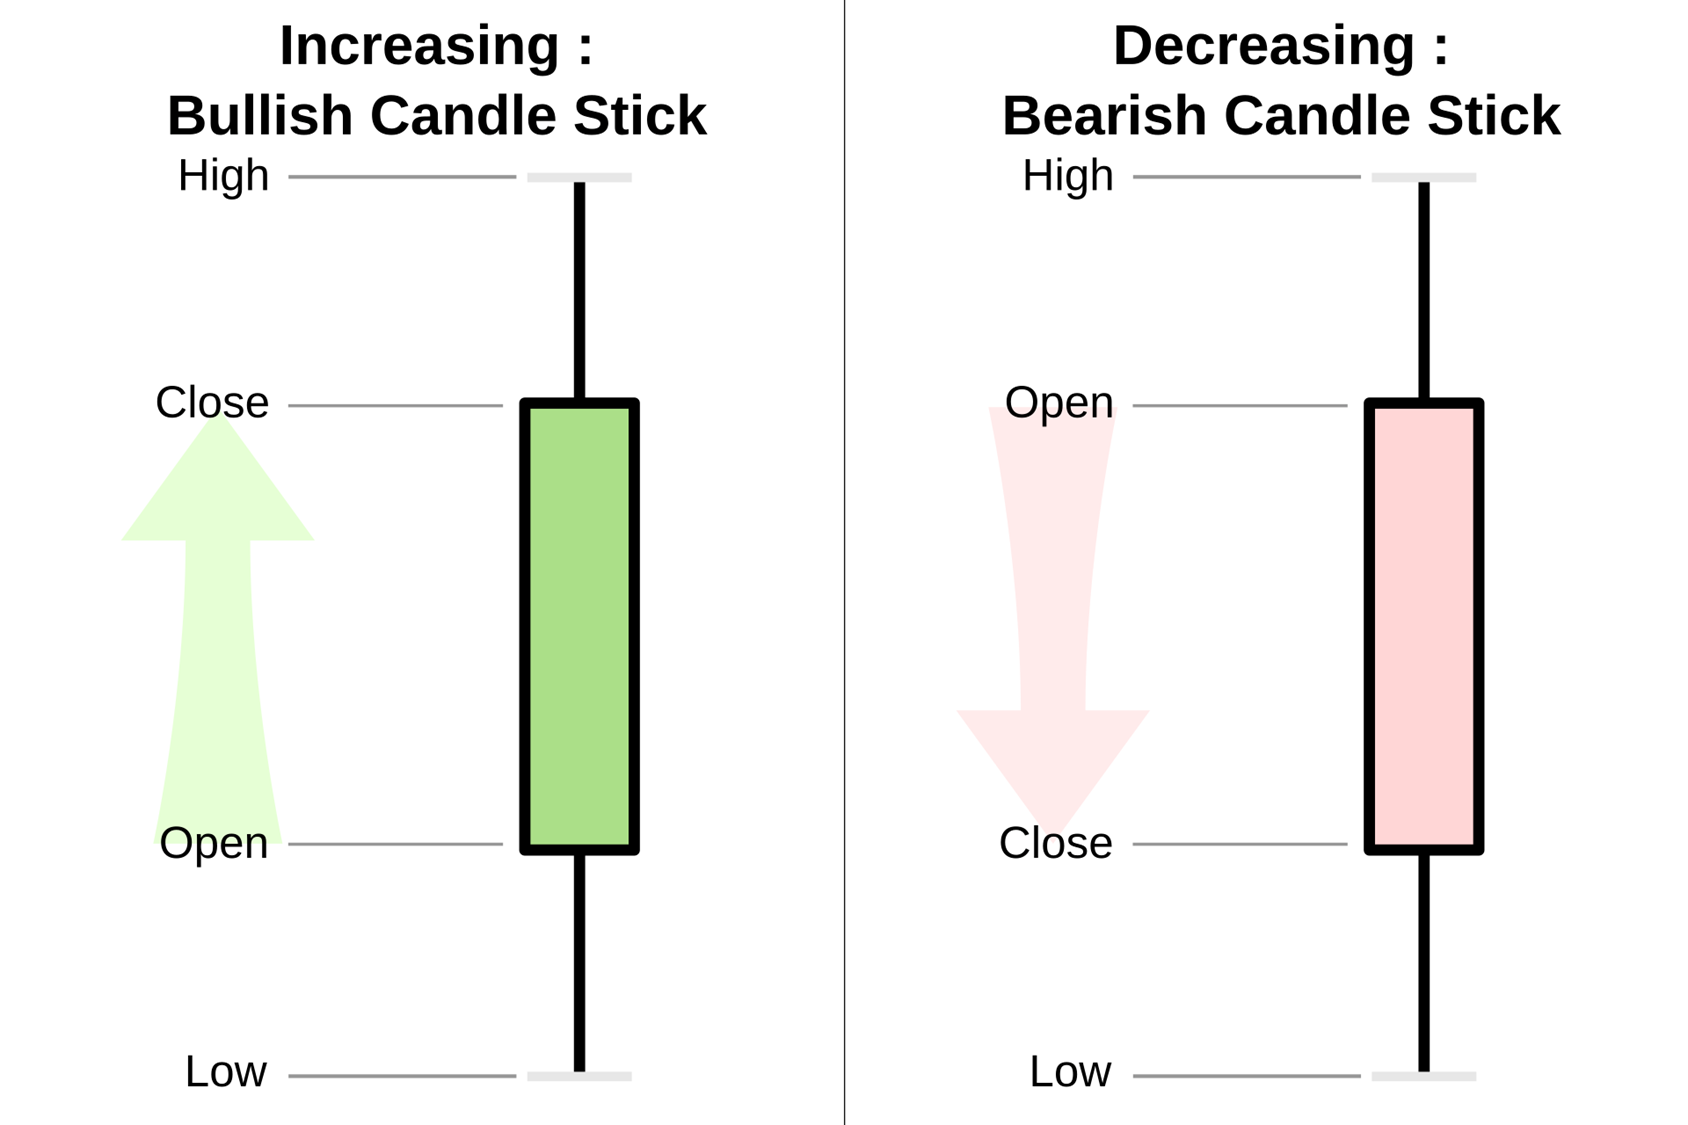

In [39]:
display(Image(filename="assets/images/candlestick_explanation.png", width=700))

### A note on adjusted prices

The prices in this lab are **adjusted** for stock splits and dividends.

When a company splits its shares, it divides each existing share into several smaller ones. In a four-to-one split, one share worth 400 becomes four shares worth 100 each. The total value is unchanged: an investor who owned one share worth 400 now owns four shares worth 100 each, which is still 400. The price per share, however, falls by three quarters overnight, and a raw price series records this as a crash even though nobody lost any money.

Adjusted prices remove such artificial jumps by rescaling the earlier history so the series is continuous. This means an adjusted price from 2016 is not the number that was displayed in 2016. For returns this does not matter. Returns measure the percentage change from one day to the next, and rescaling every price by the same factor does not change a percentage. For example, a rise from 100 to 110 is 10%, and so is a rise from 50 to 55 after everything is halved. It would matter only if we used the price itself, for example a rule such as “buy when the price is below 200”, because the rescaled prices would give different answers.

## Step 5: Plot a Candlestick Chart

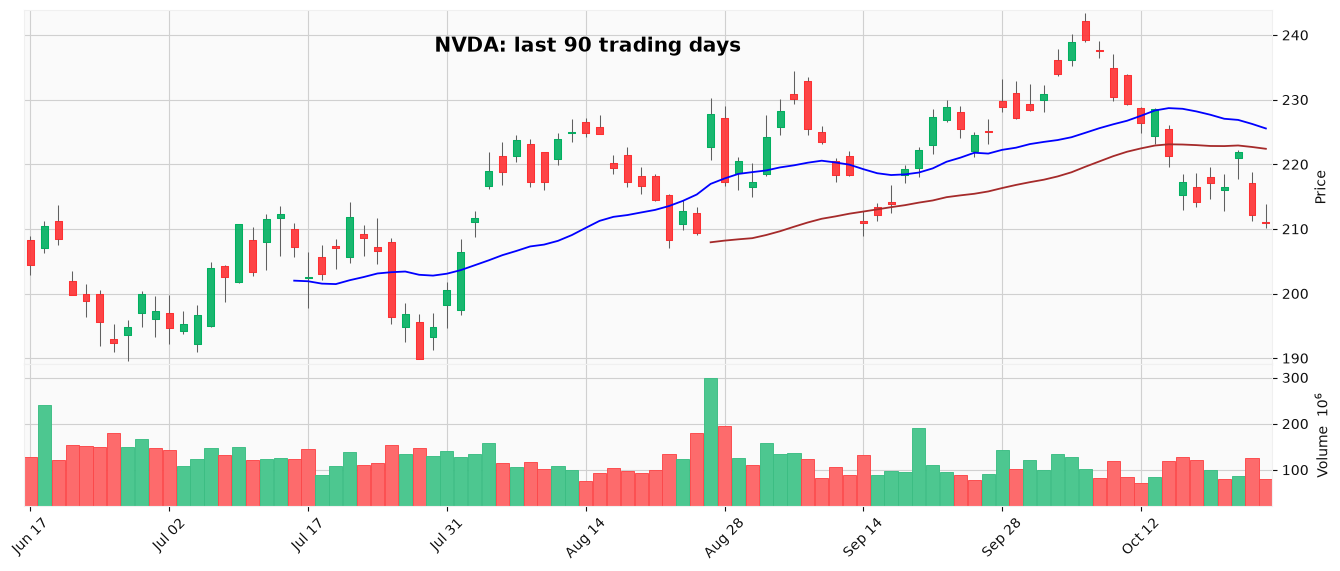

In [40]:
# The last 90 trading days, with volume and 20-day and 50-day moving averages
recent = data.tail(90)[["Open", "High", "Low", "Close", "Volume"]]
mpf.plot(
    recent, type="candle", style="yahoo", volume=True,
    mav=(20, 50), mavcolors=["blue", "brown"],
    figratio=(25, 10), tight_layout=True,
    title=f"{config.TARGET_TICKER}: last 90 trading days",
)

A **moving average** replaces each price with the average of the last *n* prices. It smooths out the daily noise so that you can see the direction of the trend. A short average (20 days) reacts quickly. A long average (50 days) reacts slowly. A common reading is that when the short average crosses above the long average, momentum has turned upward.

Notice that a moving average is, by construction, always **behind** the price. It describes the past; it does not predict the future. We will return to this point when we meet forecasts that look good only because they lag the actual price.

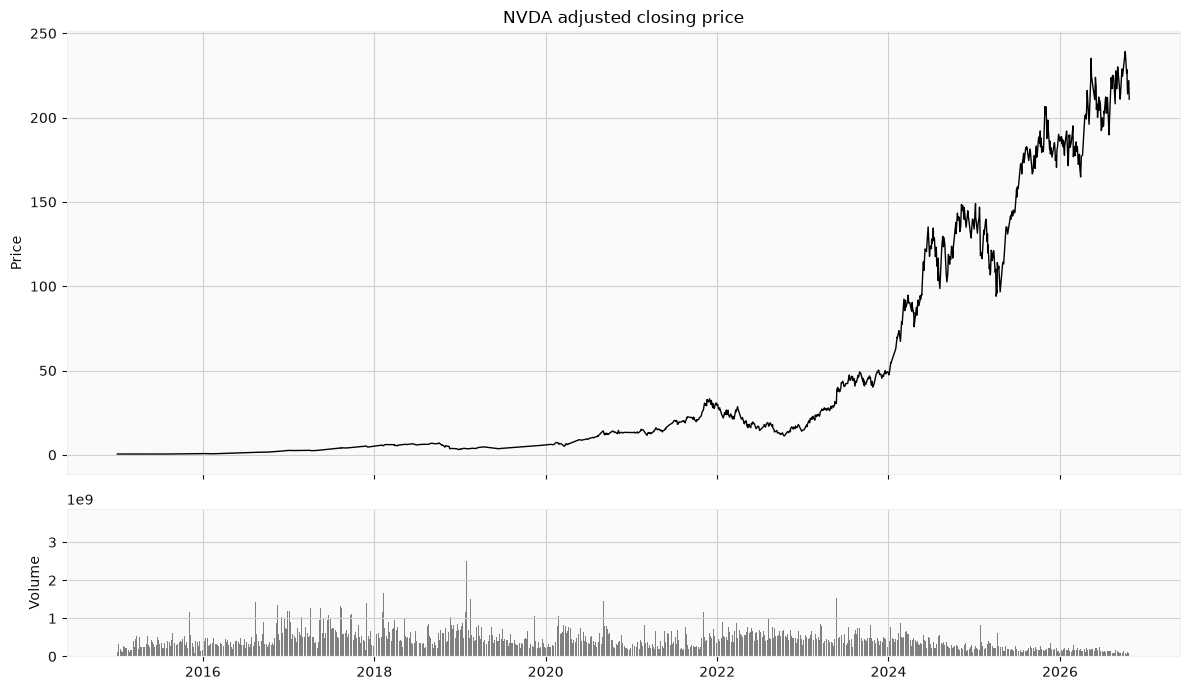

In [41]:
# The whole history of the closing price, with volume underneath

# sharex=True links the horizontal x-axis of both subplots so that zooming or panning on one automatically
# aligns with the other (sharing the same date timeline).
# gridspec_kw={"height_ratios": [3, 1]} allocates 75% of the total vertical height to the top plot (for the
# price line) and 25% to the bottom plot (for the volume bars).
fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
top.plot(data["Close"], color="black", linewidth=1)
top.set_title(f"{config.TARGET_TICKER} adjusted closing price")
top.set_ylabel("Price")
bottom.bar(data.index, data["Volume"], color="grey", width=1.5)
bottom.set_ylabel("Volume")
plt.tight_layout()
plt.show()

## Step 6: Look at the Predictors

The predictors are measured in very different units (index points, dollars, percent). To compare their shapes we **rebase** each series to 100 on the first day.

To rebase a series means to divide every value by its first value and multiply by 100, so every series starts at exactly 100 on the first day. It is similar to normalizing features, except that the reference point is the starting value.

For example, if a stock index starts at 20,000 points and later reaches 22,000, the rebased values are 100 and 110. If an exchange rate starts at 130 shillings and later reaches 143, the rebased values are also 100 and 110. Both series have risen by 10%, so they now sit on the same line even though one is in points and the other in shillings.

After rebasing, a value of 125 means “25% above the starting level”, whatever the original unit was. This is why the series can be plotted on one chart and their shapes compared directly: which one rose faster, which one fell, and when they moved together.

The formula is:

`rebased value = (value ÷ first value) × 100`

**Note:** rebasing changes only the scale, not the shape of the series. It is meant for visual comparison, not for modelling, where returns are used instead.

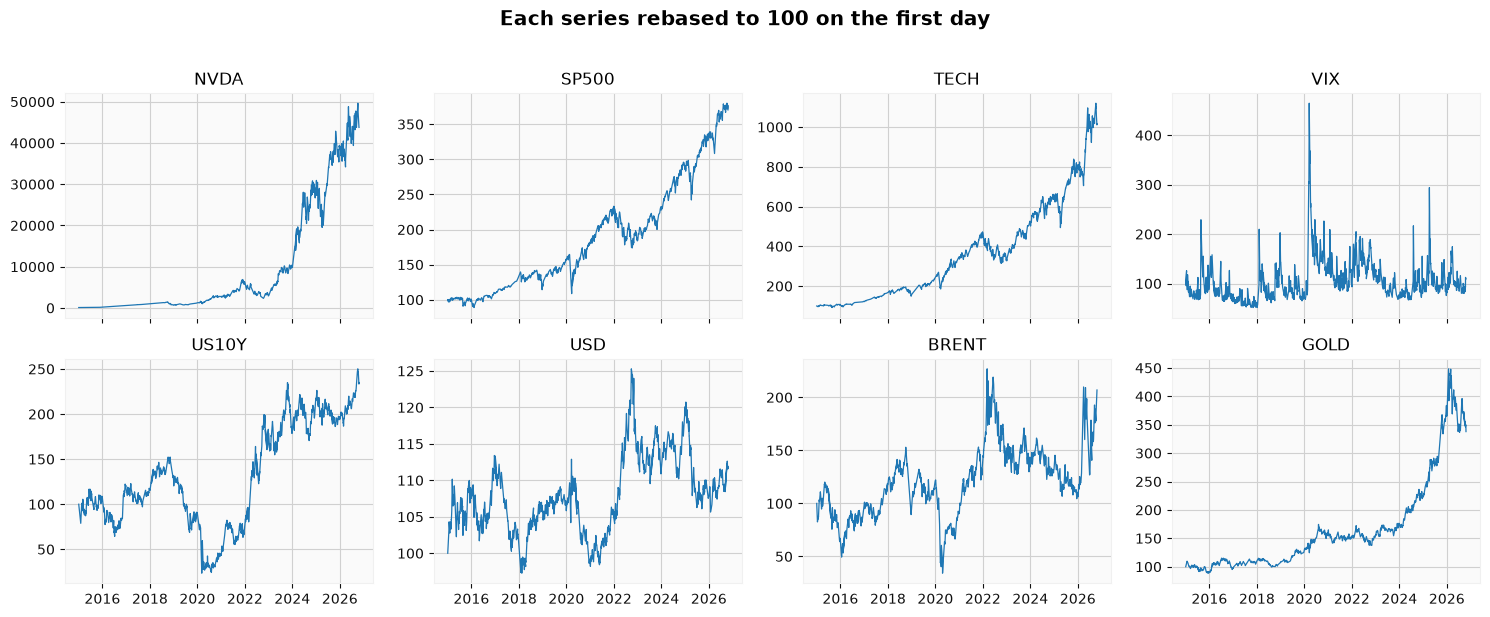

In [42]:
others = list(config.PREDICTOR_TICKERS.keys())
rebased = data[["Close"] + others].copy()
rebased = rebased / rebased.iloc[0] * 100
rebased = rebased.rename(columns={"Close": config.TARGET_TICKER})

fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex=True)
for ax, column in zip(axes.ravel(), rebased.columns):
    ax.plot(rebased[column], linewidth=0.9)
    ax.set_title(column)
plt.suptitle("Each series rebased to 100 on the first day", y=1.02)
plt.tight_layout()
plt.show()

Look at the shapes. Some series trend (the stock, the S&P 500). Some wander around a level (the VIX, interest rates). Some do both at different times. Most of them look similar to each other in places, because many things move together over years.

**That similarity is "a trap".** Two series that both trend upward over ten years will look correlated even when they have nothing to do with each other. Notebook 2 demonstrates this carefully. For now, remember that a chart of price levels is not evidence of a relationship.

## Step 7: Prices, Returns and Log Returns

Compare two ways of measuring the same day.

- **Simple return**: `(P_t - P_(t-1)) / P_(t-1)`. If the price goes from 100 to 110, the simple return is 0.10, or 10 percent.
- **Log return**: `ln(P_t / P_(t-1))`. For the same move, this is `ln(1.10) = 0.0953`.

For small moves, the two are almost identical. We prefer log returns for three practical reasons.

1. **They add up over time.** The log return over five days is the sum of the five daily log returns. Simple returns have to be multiplied.
2. **They are symmetric.** Example: a price rises 10 percent and then falls 10 percent.

In [43]:
price_today = 100.0
after_gain = price_today * 1.10
after_loss = after_gain * 0.90
print(f"Price after +10% then -10%: {after_loss:.2f}  (not 100, we lost money)")

print("Simple returns :", 0.10, -0.10, " their sum is", round(0.10 + (-0.10), 4), "(but the price is not back at 100)")
log_up = np.log(1.10)
log_down = np.log(0.90)
print(f"Log returns    : {log_up:.4f}, {log_down:.4f}  their sum is {log_up + log_down:.4f}  (the exact total change)")

Price after +10% then -10%: 99.00  (not 100, we lost money)
Simple returns : 0.1 -0.1  their sum is 0.0 (but the price is not back at 100)
Log returns    : 0.0953, -0.1054  their sum is -0.0101  (the exact total change)


3. **They are free of units.** A return of 0.01 means the same thing for a stock priced at 20 dollars and one priced at 2,000 dollars. A price change of 1 dollar does not.

We compute the daily log return for the target stock and look at how it is distributed.

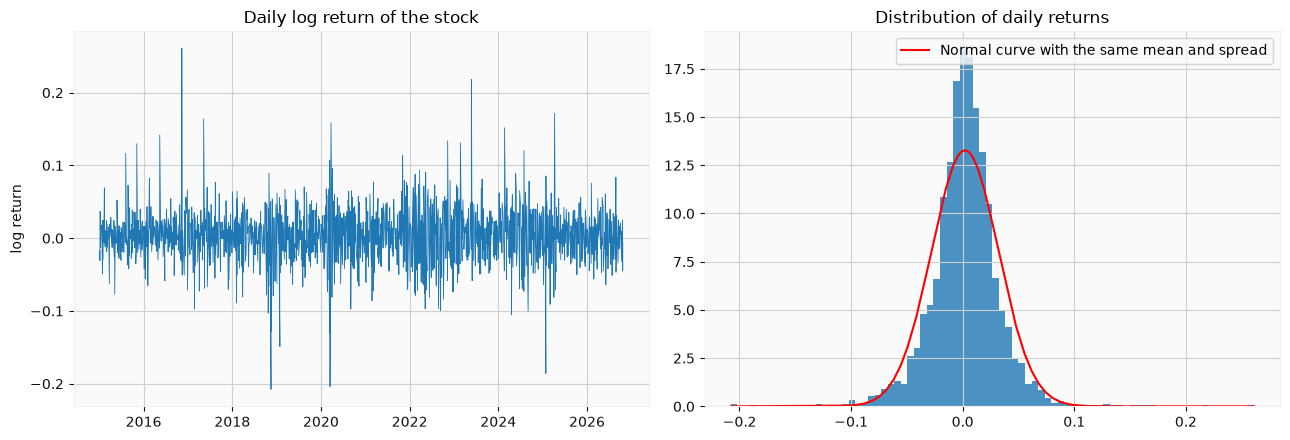

Mean daily return      : 0.00205
Standard deviation     : 0.03004
Largest one-day gain   : 0.2609
Largest one-day loss   : -0.2077


In [44]:
data["log_return"] = np.log(data["Close"]).diff()
daily = data["log_return"].dropna()

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5))
left.plot(daily, linewidth=0.6, color="tab:blue")
left.set_title("Daily log return of the stock")
left.set_ylabel("log return")

right.hist(daily, bins=80, color="tab:blue", alpha=0.8, density=True)
grid = np.linspace(daily.min(), daily.max(), 300)
normal_curve = np.exp(-0.5 * ((grid - daily.mean()) / daily.std()) ** 2) / (daily.std() * np.sqrt(2 * np.pi))
right.plot(grid, normal_curve, color="red", label="Normal curve with the same mean and spread")
right.set_title("Distribution of daily returns")
right.legend()
plt.tight_layout()
plt.show()

print(f"Mean daily return      : {daily.mean():.5f}")
print(f"Standard deviation     : {daily.std():.5f}")
print(f"Largest one-day gain   : {daily.max():.4f}")
print(f"Largest one-day loss   : {daily.min():.4f}")

Two features of the plot on the left are important for everything that follows.

1. The returns fluctuate around zero. There is no trend and the level does not wander away. This is what a **stationary** series looks like (Notebook 2).
2. The size of the swings changes over time. Calm periods are followed by wild ones. This is called **volatility clustering**, and it is one of the most reliable facts about financial markets.

The histogram on the right shows that real returns have **fatter tails** than the normal curve: extreme days happen more often than a normal distribution allows. Any method that assumes normal errors will underestimate the risk of a bad day.

## Step 8: Daily Correlation Between the Markets

How do the markets move together from one day to the next? We compute daily returns for every series (differences for the interest rate, because it is a rate and not a price) and look at their correlations.

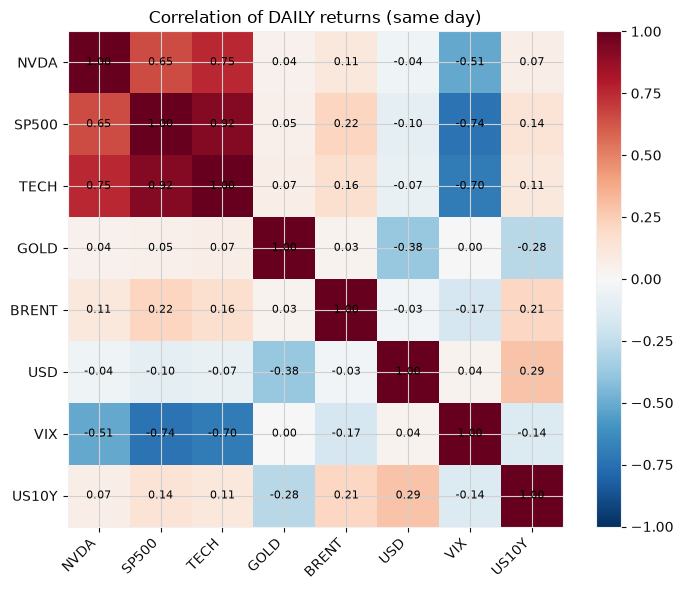

In [45]:
returns = pd.DataFrame(index=data.index)
returns[config.TARGET_TICKER] = np.log(data["Close"]).diff()
for name in ["SP500", "TECH", "GOLD", "BRENT", "USD", "VIX"]:
    returns[name] = np.log(data[name]).diff()
returns["US10Y"] = data["US10Y"].diff()
returns = returns.dropna()

correlation = returns.corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
image = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation))); ax.set_xticklabels(correlation.columns, rotation=45, ha="right")
ax.set_yticks(range(len(correlation))); ax.set_yticklabels(correlation.columns)
for i in range(len(correlation)):
    for j in range(len(correlation)):
        ax.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(image)
ax.set_title("Correlation of DAILY returns (same day)")
plt.tight_layout()
plt.show()

This heatmap shows **same-day** correlations. The stock is strongly correlated with the S&P 500 and the technology fund on the same day, and negatively correlated with the VIX (when the market falls, fear rises).

Be careful with what this tells you. A same-day correlation is **not** a forecast. To forecast tomorrow's stock return you need a relationship between **today's** predictor values and **tomorrow's** stock return. We test that in Notebook 4, and you should be prepared to find that it is much weaker than the heatmap above.

## Step 9: Exercises

Answer these in your own words in the lab submission file. Short answers (two to four sentences) are enough.

1. In the data quality report, which line would worry you most if it were not zero, and why?
2. A colleague says: "The S&P 500 correlates 0.7 with our stock, so it will be an excellent predictor." What is missing from that argument? (Hint: look at the note on timing in Step 2.)
3. Rerun Step 5 for a different 90-day window, for example `data.loc["2020-02-01":"2020-04-30"]`. What does the volume do when the price falls sharply? Why might that be?
4. A stock price rises 50 percent in year one and falls 50 percent in year two. What is the total simple return? What is the total log return?
5. Look at the right-hand histogram in Step 7. Name one decision in risk management that would be wrong if you assumed that returns follow the red curve.

## Summary

- A trading day is summarised by Open, High, Low, Close and Volume. We forecast the Close.
- We use several predictors from other markets because a decision maker looks at more than one number.
- Always check the quality of the data before modelling.
- Returns, not prices, are the natural quantity to model. The next notebook shows why in detail.